In [ ]:
from google.colab import files

uploaded = files.upload()

zip_file = next(
    name for name in uploaded
    if name.lower().endswith(".zip")
)

print("Uploaded:", zip_file)

Saving clothing_composition_label_dataset_100.zip to clothing_composition_label_dataset_100.zip
Uploaded: clothing_composition_label_dataset_100.zip


In [ ]:
import zipfile
import os
import glob

EXTRACT_DIR = "/content/greenwardrobe_dataset"

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(zip_file, "r") as z:
    z.extractall(EXTRACT_DIR)

# Automatically locate CSV
csv_files = glob.glob(
    EXTRACT_DIR + "/**/labels_metadata.csv",
    recursive=True
)

assert len(csv_files) > 0, "CSV file not found!"

CSV_PATH = csv_files[0]
DATA_ROOT = os.path.dirname(CSV_PATH)

IMAGE_DIR = os.path.join(DATA_ROOT, "images")

print("CSV:", CSV_PATH)
print("Image directory:", IMAGE_DIR)
print("Number of images:", len(glob.glob(IMAGE_DIR + "/*.jpg")))

CSV: /content/greenwardrobe_dataset/clothing_composition_label_dataset_500/labels_metadata.csv
Image directory: /content/greenwardrobe_dataset/clothing_composition_label_dataset_500/images
Number of images: 500


In [ ]:
!pip install -q easyocr jiwer opencv-python-headless pandas matplotlib seaborn

In [ ]:
import pandas as pd
import numpy as np
import ast

df = pd.read_csv(CSV_PATH)

print("Total CSV records:", len(df))
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())

required_columns = [
    "image",
    "made_in",
    "rn_number",
    "ca_number",
    "composition",
    "care_instructions"
]

for col in required_columns:
    assert col in df.columns, f"Missing column: {col}"

assert len(df) == 100, "Expected 100 records"

Total CSV records: 100

Columns:
['image', 'made_in', 'rn_number', 'ca_number', 'composition', 'composition_json', 'care_instructions', 'washing_symbols', 'synthetic']

First five records:


,image,made_in,rn_number,ca_number,composition,composition_json,care_instructions,washing_symbols,synthetic
0,images/label_0001.jpg,ITALY,RN#433248,CA#810931,16% ACRYLIC; 84% WOOL,"{'ACRYLIC': 16, 'WOOL': 84}",MACHINE WASH 30°C; GENTLE CYCLE; DO NOT BLEACH...,wash_30C; bleach_do_not; tumble_dry_symbol; ir...,True
1,images/label_0002.jpg,INDIA,RN#378711,CA#170535,68% NYLON; 32% WOOL,"{'NYLON': 68, 'WOOL': 32}",WASH WITH LIKE COLOURS; MACHINE WASH COLD; DO ...,wash_30C; bleach_do_not; tumble_dry_symbol; ir...,True
2,images/label_0003.jpg,VIETNAM,RN#680901,CA#608288,100% LINEN,{'LINEN': 100},MACHINE WASH 30°C; DO NOT BLEACH; DO NOT TUMBL...,wash_30C; bleach_do_not; tumble_dry_symbol; ir...,True
3,images/label_0004.jpg,PORTUGAL,RN#688091,CA#253281,34% SILK; 66% POLYESTER,"{'SILK': 34, 'POLYESTER': 66}",MACHINE WASH 40°C; DO NOT BLEACH; TUMBLE DRY L...,wash_30C; bleach_do_not; tumble_dry_symbol; ir...,True
4,images/label_0005.jpg,PAKISTAN,RN#755860,CA#394247,100% ACRYLIC,{'ACRYLIC': 100},MACHINE WASH 30°C; GENTLE CYCLE; DO NOT BLEACH...,wash_30C; bleach_do_not; tumble_dry_symbol; ir...,True


In [ ]:
import easyocr
import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Available device:", DEVICE)

reader = easyocr.Reader(
    ["en"],
    gpu=(DEVICE == "cuda")
)

print("EasyOCR model loaded successfully!")

Available device: cpu
EasyOCR model loaded successfully!


In [ ]:
import cv2

def preprocess_image(image_path):

    image = cv2.imread(image_path)

    if image is None:
        raise ValueError("Unable to read image: " + image_path)

    # Resize image for better character visibility
    image = cv2.resize(
        image,
        None,
        fx=1.5,
        fy=1.5,
        interpolation=cv2.INTER_CUBIC
    )

    # Convert to grayscale
    gray = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY
    )

    # Improve local contrast
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(gray)

    # Sharpen image
    blurred = cv2.GaussianBlur(
        enhanced,
        (0, 0),
        1.0
    )

    sharpened = cv2.addWeighted(
        enhanced, 1.5,
        blurred, -0.5,
        0
    )

    return sharpened

In [ ]:
from tqdm.notebook import tqdm

def extract_text(image_path):

    processed = preprocess_image(image_path)

    results = reader.readtext(
        processed,
        detail=1,
        paragraph=False
    )

    # Sort detected text regions from top to bottom,
    # then left to right.
    results = sorted(
        results,
        key=lambda item: (
            sum(point[1] for point in item[0]) / 4,
            sum(point[0] for point in item[0]) / 4
        )
    )

    extracted_lines = []
    confidences = []

    for bbox, text, confidence in results:
        extracted_lines.append(text)
        confidences.append(float(confidence))

    complete_text = "\n".join(extracted_lines)

    avg_confidence = (
        np.mean(confidences)
        if confidences else 0
    )

    return complete_text, avg_confidence


# Process every image without splitting
predicted_texts = []
ocr_confidences = []
processing_errors = []

for idx, row in tqdm(
    df.iterrows(),
    total=len(df),
    desc="Extracting text"
):

    image_path = os.path.join(
        DATA_ROOT,
        row["image"]
    )

    try:
        text, confidence = extract_text(image_path)

    except Exception as e:
        text = ""
        confidence = 0

        processing_errors.append({
            "image": row["image"],
            "error": str(e)
        })

    predicted_texts.append(text)
    ocr_confidences.append(confidence)


df["predicted_text"] = predicted_texts
df["ocr_confidence"] = ocr_confidences

print("OCR processing completed!")
print("Processed records:", len(df))
print("Processing errors:", len(processing_errors))

Extracting text:   0%|          | 0/100 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


OCR processing completed!
Processed records: 100
Processing errors: 0


In [ ]:
def build_ground_truth(row):

    care_items = [
        item.strip()
        for item in str(row["care_instructions"]).split(";")
    ]

    care_items = care_items[:3]

    expected_text = f"""
MADE IN {row['made_in']}
{row['rn_number']} / {row['ca_number']}
FABRIC COMPOSITION
{row['composition'].replace(';', chr(10))}
CARE INSTRUCTIONS
{chr(10).join(care_items)}
"""

    return expected_text.strip()


df["ground_truth_text"] = df.apply(
    build_ground_truth,
    axis=1
)

display(
    df[[
        "image",
        "ground_truth_text",
        "predicted_text"
    ]].head(5)
)

,image,ground_truth_text,predicted_text
0,images/label_0001.jpg,MADE IN ITALY\nRN#433248 / CA#810931\nFABRIC C...,MADE IN ITALY\nRN# 433248 / CA# 810931\nFABRIC...
1,images/label_0002.jpg,MADE IN INDIA\nRN#378711 / CA#170535\nFABRIC C...,MADE IN INDIA\nRN# 378711 / CA# 170535\nFABRIC...
2,images/label_0003.jpg,MADE IN VIETNAM\nRN#680901 / CA#608288\nFABRIC...,MADE IN VIETNAM\nRN# 680901 / CA# 608288\nFABR...
3,images/label_0004.jpg,MADE IN PORTUGAL\nRN#688091 / CA#253281\nFABRI...,MADE IN PORTUGAL\nRN# 688091 / CA# 253281\nFAB...
4,images/label_0005.jpg,MADE IN PAKISTAN\nRN#755860 / CA#394247\nFABRI...,MADE IN PAKISTAN\nRN# 755860 / CA# 394247\nFAB...


In [ ]:
import re
from jiwer import cer, wer

def normalize_text(text):

    text = str(text).upper()

    text = text.replace("％", "%")
    text = text.replace("° C", "°C")

    # Standardize whitespace and punctuation spacing
    text = re.sub(r'\s+', ' ', text)

    return text.strip()


df["actual_normalized"] = df[
    "ground_truth_text"
].apply(normalize_text)

df["predicted_normalized"] = df[
    "predicted_text"
].apply(normalize_text)


# CER and WER are calculated across all records.
actual_all = df["actual_normalized"].tolist()
predicted_all = df["predicted_normalized"].tolist()

full_cer = cer(actual_all, predicted_all)
full_wer = wer(actual_all, predicted_all)

character_accuracy = max(0, 1 - full_cer) * 100
word_accuracy = max(0, 1 - full_wer) * 100

df["full_text_exact_match"] = (
    df["actual_normalized"] ==
    df["predicted_normalized"]
)

exact_text_accuracy = (
    df["full_text_exact_match"].mean() * 100
)

print("========== FULL TEXT OCR RESULTS ==========")

print(f"Total images: {len(df)}")
print(f"Character Error Rate: {full_cer:.4f}")
print(f"Word Error Rate: {full_wer:.4f}")
print(f"Character Accuracy Estimate: {character_accuracy:.2f}%")
print(f"Word Accuracy Estimate: {word_accuracy:.2f}%")
print(f"Exact Full Text Accuracy: {exact_text_accuracy:.2f}%")

========== FULL TEXT OCR RESULTS ==========
Total images: 100
Character Error Rate: 0.0712
Word Error Rate: 0.3055
Character Accuracy Estimate: 92.88%
Word Accuracy Estimate: 69.45%
Exact Full Text Accuracy: 0.00%


In [ ]:
FIBRES = [
    "COTTON",
    "POLYESTER",
    "VISCOSE",
    "ELASTANE",
    "NYLON",
    "WOOL",
    "ACRYLIC",
    "LINEN",
    "MODAL",
    "SILK"
]

def extract_composition(text):

    text = str(text).upper()

    # Normalize common OCR errors in percentage notation
    text = text.replace("％", "%")

    extracted = {}

    for fibre in FIBRES:

        pattern = (
            r'(?<!\d)(\d{1,3})\s*%\s*'
            + fibre
            + r'\b'
        )

        matches = re.findall(pattern, text)

        if matches:
            extracted[fibre] = int(matches[0])

    return extracted


def parse_actual_composition(text):

    result = {}

    for part in str(text).split(";"):

        match = re.search(
            r'(\d+)\s*%\s*(.+)',
            part.strip()
        )

        if match:
            percentage = int(match.group(1))
            fibre = match.group(2).strip().upper()

            result[fibre] = percentage

    return result


df["actual_composition_dict"] = df[
    "composition"
].apply(parse_actual_composition)

df["predicted_composition_dict"] = df[
    "predicted_text"
].apply(extract_composition)

display(
    df[[
        "composition",
        "predicted_composition_dict"
    ]].head(10)
)

,composition,predicted_composition_dict
0,16% ACRYLIC; 84% WOOL,{'WOOL': 84}
1,68% NYLON; 32% WOOL,"{'NYLON': 68, 'WOOL': 32}"
2,100% LINEN,{'LINEN': 100}
3,34% SILK; 66% POLYESTER,"{'POLYESTER': 66, 'SILK': 34}"
4,100% ACRYLIC,{'ACRYLIC': 100}
5,24% NYLON; 76% VISCOSE,"{'VISCOSE': 76, 'NYLON': 24}"
6,83% ELASTANE; 17% MODAL,"{'ELASTANE': 83, 'MODAL': 17}"
7,20% ELASTANE; 80% COTTON,"{'COTTON': 80, 'ELASTANE': 20}"
8,35% COTTON; 65% VISCOSE,"{'COTTON': 35, 'VISCOSE': 65}"
9,31% COTTON; 69% ACRYLIC,{'ACRYLIC': 31}


In [ ]:
df["composition_correct"] = df.apply(
    lambda row:
        row["actual_composition_dict"] ==
        row["predicted_composition_dict"],
    axis=1
)

composition_accuracy = (
    df["composition_correct"].mean() * 100
)

print("========== COMPOSITION ACCURACY ==========")

print("Total images:", len(df))

print(
    "Correct compositions:",
    df["composition_correct"].sum()
)

print(
    "Incorrect compositions:",
    (~df["composition_correct"]).sum()
)

print(
    f"Exact Composition Accuracy: "
    f"{composition_accuracy:.2f}%"
)

========== COMPOSITION ACCURACY ==========
Total images: 100
Correct compositions: 90
Incorrect compositions: 10
Exact Composition Accuracy: 90.00%


In [ ]:
total_fibres = 0
correct_fibres = 0

total_percentages = 0
correct_percentages = 0

for _, row in df.iterrows():

    actual = row["actual_composition_dict"]
    predicted = row["predicted_composition_dict"]

    for fibre, percentage in actual.items():

        total_fibres += 1
        total_percentages += 1

        if fibre in predicted:
            correct_fibres += 1

        if predicted.get(fibre) == percentage:
            correct_percentages += 1


fibre_accuracy = (
    correct_fibres / total_fibres * 100
    if total_fibres else 0
)

percentage_accuracy = (
    correct_percentages / total_percentages * 100
    if total_percentages else 0
)

print("========== COMPONENT ACCURACY ==========")

print(f"Fibre Name Accuracy: {fibre_accuracy:.2f}%")

print(f"Percentage Accuracy: {percentage_accuracy:.2f}%")

========== COMPONENT ACCURACY ==========
Fibre Name Accuracy: 95.34%
Percentage Accuracy: 93.78%


In [ ]:
def clean_field(text):
    return re.sub(
        r'[^A-Z0-9]+',
        '',
        str(text).upper()
    )


def extract_country(text):

    match = re.search(
        r'MADE\s+IN\s+([A-Z]+)',
        str(text).upper()
    )

    return match.group(1) if match else ""


def extract_number(text, prefix):

    match = re.search(
        rf'{prefix}\s*#?\s*(\d{{5,7}})',
        str(text).upper()
    )

    return match.group(1) if match else ""


def field_match(actual, predicted):

    return clean_field(actual) == clean_field(predicted)


country_correct = []
rn_correct = []
ca_correct = []
care_correct = []

for _, row in df.iterrows():

    predicted = row["predicted_text"]

    country_pred = extract_country(predicted)

    rn_pred = extract_number(predicted, "RN")
    ca_pred = extract_number(predicted, "CA")

    # Only the first three instructions are visible in the image
    actual_care = [
        x.strip()
        for x in str(row["care_instructions"]).split(";")
    ][:3]

    normalized_prediction = normalize_text(predicted)

    care_ok = all(
        clean_field(item) in clean_field(normalized_prediction)
        for item in actual_care
    )

    country_correct.append(
        field_match(row["made_in"], country_pred)
    )

    rn_correct.append(
        field_match(
            str(row["rn_number"]).replace("RN#", ""),
            rn_pred
        )
    )

    ca_correct.append(
        field_match(
            str(row["ca_number"]).replace("CA#", ""),
            ca_pred
        )
    )

    care_correct.append(care_ok)


df["country_correct"] = country_correct
df["rn_correct"] = rn_correct
df["ca_correct"] = ca_correct
df["care_correct"] = care_correct


print("========== FIELD-WISE ACCURACY ==========")

for name, values in [
    ("Country", country_correct),
    ("RN Number", rn_correct),
    ("CA Number", ca_correct),
    ("Care Instructions", care_correct)
]:

    print(
        f"{name}: {np.mean(values) * 100:.2f}%"
    )

========== FIELD-WISE ACCURACY ==========
Country: 98.00%
RN Number: 96.00%
CA Number: 97.00%
Care Instructions: 38.00%


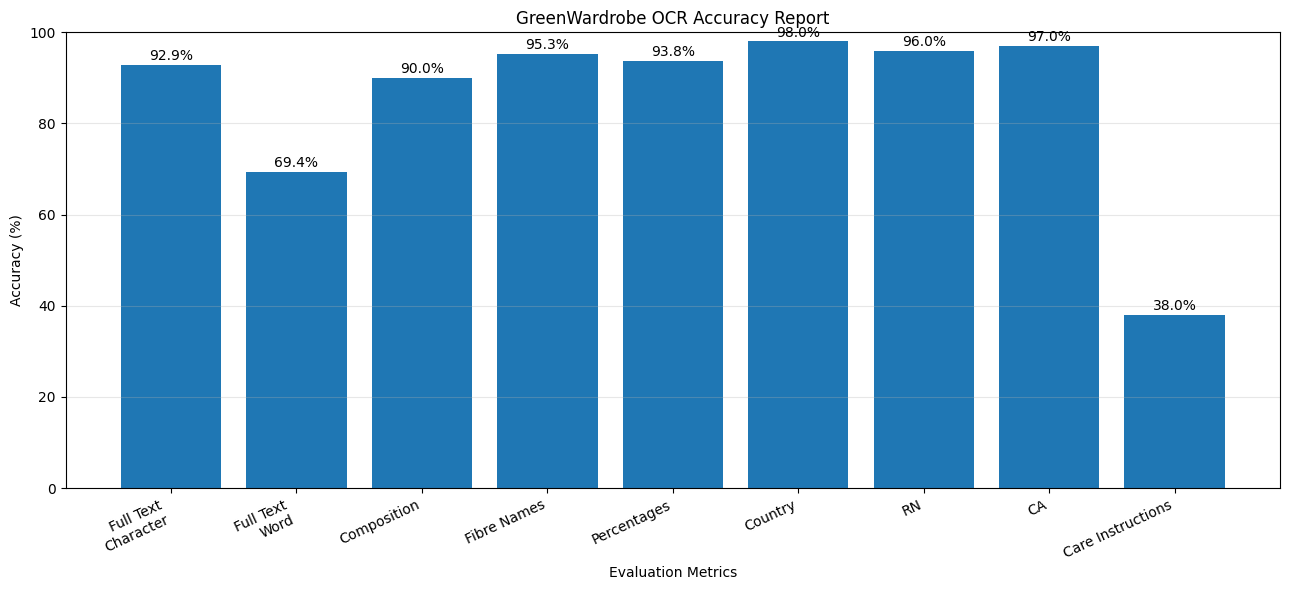

In [ ]:
import matplotlib.pyplot as plt

metrics = {
    "Full Text\nCharacter": character_accuracy,
    "Full Text\nWord": word_accuracy,
    "Composition": composition_accuracy,
    "Fibre Names": fibre_accuracy,
    "Percentages": percentage_accuracy,
    "Country": np.mean(country_correct) * 100,
    "RN": np.mean(rn_correct) * 100,
    "CA": np.mean(ca_correct) * 100,
    "Care Instructions": np.mean(care_correct) * 100
}

plt.figure(figsize=(13, 6))

plt.bar(
    metrics.keys(),
    metrics.values()
)

plt.ylim(0, 100)

plt.ylabel("Accuracy (%)")
plt.xlabel("Evaluation Metrics")
plt.title("GreenWardrobe OCR Accuracy Report")

plt.xticks(rotation=25, ha="right")

plt.grid(axis="y", alpha=0.3)

for i, value in enumerate(metrics.values()):
    plt.text(
        i,
        value + 1,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [ ]:
incorrect = df[
    (~df["composition_correct"]) |
    (~df["full_text_exact_match"])
]

print("Total images with errors:", len(incorrect))

for _, row in incorrect.head(20).iterrows():

    print("\nIMAGE:", row["image"])

    print("\nEXPECTED COMPOSITION:")
    print(row["composition"])

    print("\nEXTRACTED COMPOSITION:")
    print(row["predicted_composition_dict"])

    print("\nEXPECTED FULL TEXT:")
    print(row["ground_truth_text"])

    print("\nOCR EXTRACTED TEXT:")
    print(row["predicted_text"])

    print("=" * 80)

Total images with errors: 100

IMAGE: images/label_0001.jpg

EXPECTED COMPOSITION:
16% ACRYLIC; 84% WOOL

EXTRACTED COMPOSITION:
{'WOOL': 84}

EXPECTED FULL TEXT:
MADE IN ITALY
RN#433248 / CA#810931
FABRIC COMPOSITION
16% ACRYLIC
 84% WOOL
CARE INSTRUCTIONS
MACHINE WASH 30°C
GENTLE CYCLE
DO NOT BLEACH

OCR EXTRACTED TEXT:
MADE IN ITALY
RN# 433248 / CA# 810931
FABRIC COMPOSITION
16 ACRYLIC
84% WOOL
CARE INSTRUCTIONS
MACHINE WASH 30*C
GENTLE CYCLE
DQ NOT RLEACH

IMAGE: images/label_0002.jpg

EXPECTED COMPOSITION:
68% NYLON; 32% WOOL

EXTRACTED COMPOSITION:
{'NYLON': 68, 'WOOL': 32}

EXPECTED FULL TEXT:
MADE IN INDIA
RN#378711 / CA#170535
FABRIC COMPOSITION
68% NYLON
 32% WOOL
CARE INSTRUCTIONS
WASH WITH LIKE COLOURS
MACHINE WASH COLD
DO NOT BLEACH

OCR EXTRACTED TEXT:
MADE IN INDIA
RN# 378711 / CA# 170535
FABRIC COMPOSITION
68% NYLON
32% WOOL
CARE INSTRUCTIONS
WASH WITH LIKE COLOURS
MACHINE WASH COLD
DO
NOTRLEACIJ

IMAGE: images/label_0003.jpg

EXPECTED COMPOSITION:
100% LINEN

EXTRACTED

In [ ]:
OUTPUT_DIR = "/content/greenwardrobe_results"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Complete results
df.to_csv(
    OUTPUT_DIR + "/all_500_ocr_results.csv",
    index=False
)

# Incorrect predictions
incorrect.to_csv(
    OUTPUT_DIR + "/incorrect_predictions.csv",
    index=False
)

# Summary report
summary = pd.DataFrame(
    list(metrics.items()),
    columns=["Metric", "Accuracy_Percentage"]
)

summary.loc[len(summary)] = [
    "Exact Full Text Match",
    exact_text_accuracy
]

summary.to_csv(
    OUTPUT_DIR + "/accuracy_summary.csv",
    index=False
)

print("All reports generated successfully!")

All reports generated successfully!


In [ ]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/GreenWardrobe_OCR_Evaluation",
    "zip",
    OUTPUT_DIR
)

files.download(
    "/content/GreenWardrobe_OCR_Evaluation.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>